<a href="https://colab.research.google.com/github/LuizCunha4/NRE/blob/main/SME0300_Laboratorio_Polinomios_Trigonometricos_Alunos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SME0300 — Laboratório: mínimos quadrados e polinômios trigonométricos

**Objetivos.** Calcular os coeficientes de Fourier por integração numérica; generalizar o cálculo dos polinômios trigonométricos para ordens arbitrárias; investigar a influência da ordem, e da extensão periódica na aproximação; aplicar uma mudança de variável para intervalos arbitrários.

Considere $f:[-\pi,\pi]\to\mathbb R$. Procuramos o polinômio de ordem $m$

$$p_m(x)=\frac{a_0}{2}+\sum_{k=1}^{m}\bigl[a_k\cos(kx)+b_k\sin(kx)\bigr]$$

que minimiza

$$J(p_m)=\int_{-\pi}^{\pi}[f(x)-p_m(x)]^2\,dx.$$

Pela ortogonalidade das funções trigonométricas,

$$a_k=\frac1\pi\int_{-\pi}^{\pi}f(x)\cos(kx)\,dx\quad(k=0,\ldots,m),$$
$$b_k=\frac1\pi\int_{-\pi}^{\pi}f(x)\sin(kx)\,dx\quad(k=1,\ldots,m).$$

**Orientações:** execute as células na ordem; utilize um método de integração estudado em aula. A função `diagnostico` é fornecida para apoiar a interpretação gráfica. O erro exibido é calculado em uma malha uniforme do intervalo $[-\pi,\pi]$, enquanto o polinômio é apresentado em $[-2\pi,2\pi]$.

**Entrega:** responda o que se pede. Ao final, envie o arquivo .ipynb e envie ao email do PAE victorcunha@usp.br até dia 22/11 às 23:59h. Esta atividade vale até 0.5 pto na P2.


**Conteúdo do Email:** Arquivo .ipynb notebook, com os gráficos e as respostas às questões de análise.

Título do email : [NUSP]_NomeCompleto_SM0300_LabMQM



### Preparação — execute esta célula antes de iniciar

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#@title Função para plotar os gráficos
def diagnostico(f, a, b, titulo, pontos=10000):

    # Intervalo original: cálculo dos erros
    x = np.linspace(-np.pi, np.pi, pontos, endpoint=False)
    y = f(x)
    norma_f = np.linalg.norm(y)

    # Intervalo estendido: visualização
    xl = np.linspace(-2*np.pi, 2*np.pi, 2*pontos, endpoint=False)

    m = len(a) - 1

    # Polinômio no intervalo original
    p = (a[0] / 2) * np.ones_like(x)

    # Polinômio no intervalo estendido
    pl = (a[0] / 2) * np.ones_like(xl)

    erros = [np.linalg.norm(y - p) / norma_f]

    # Construção progressiva dos polinômios
    for k in range(1, m + 1):

        # Intervalo original (erro)
        p = p + a[k]*np.cos(k*x) + b[k]*np.sin(k*x)

        # Intervalo estendido (gráfico)
        pl = pl + a[k]*np.cos(k*xl) + b[k]*np.sin(k*xl)

        erro_relativo = np.linalg.norm(y - p) / norma_f
        erros.append(erro_relativo)

    fig, (ax_ajuste, ax_coef, ax_erro) = plt.subplots(
        1, 3, figsize=(14, 4), layout="constrained"
    )

    # Função original e extensão periódica do polinômio
    ax_ajuste.plot(xl, pl, label=f"Aproximação de ordem {m}")
    ax_ajuste.plot(x, y, label="f(x)", color="black", linewidth=2, zorder=2)
    ax_ajuste.set_title("Função e aproximação")
    ax_ajuste.set_xlabel("x")
    ax_ajuste.set_xlim(-2*np.pi, 2*np.pi)
    ax_ajuste.set_xticks(
        [-2*np.pi, -np.pi, 0, np.pi, 2*np.pi],
        [r"$-2\pi$", r"$-\pi$", "0", r"$\pi$", r"$2\pi$"]
    )
    ax_ajuste.legend()

    # Coeficientes de Fourier
    indices = range(1, m + 1)
    ax_coef.plot(indices, np.abs(a[1:]), "o-", label=r"$|a_k|$")
    ax_coef.plot(indices, np.abs(b[1:]), "x--", label=r"$|b_k|$")
    ax_coef.set_title("Coeficientes de Fourier")
    ax_coef.set_xlabel("Índice k")
    ax_coef.legend()

    # Erro relativo
    ax_erro.plot(range(m + 1), erros, "o-")
    ax_erro.set_title("Erro relativo em norma 2")
    ax_erro.set_xlabel("Ordem k")
    ax_erro.set_ylabel(r"$\|f-p_k\|_2\,/\,\|f\|_2$")

    fig.suptitle(titulo)
    plt.show()

    return np.array(erros)

## Exercício 7 — Polinômio trigonométrico de ordem 1

Considere $f(x)=|x|$, para $x\in[-\pi,\pi]$.

**Tarefa 001 — Integração numérica.** Implemente ou recupere uma rotina de integração numérica estudada em aula. Empregue pelo menos 200 subintervalos ou pontos, conforme o método escolhido. Utilize a rotina para calcular os coeficientes de Fourier.

**Tarefa 002 — Aproximação de ordem 1.** Calcule $a_0$, $a_1$ e $b_1$ e construa

$$p_1(x)=\frac{a_0}{2}+a_1\cos x+b_1\sin x.$$

Apresente os coeficientes e examine os gráficos.

**Responda:** (a) Pela simetria de $|x|$, o que se espera de $b_1$? (b) A aproximação reproduz satisfatoriamente o comportamento de $f$ em todo o intervalo?

In [ ]:
# Exemplo fornecido: quadratura de Gauss-Legendre com n pontos
import numpy as np

def quadgauss(f, n, a, b):
  def g(x):
    return f((b-a)*x/2+(a+b)/2)*(b-a)/2
  xi, wi = np.polynomial.legendre.leggauss(n)
  aux = 0
  for i in range(n):
    aux += wi[i]*g(xi[i])
  return aux

a0 = 3.141656929666, a1 = -1.273175255028, b1 = 0.000000000000


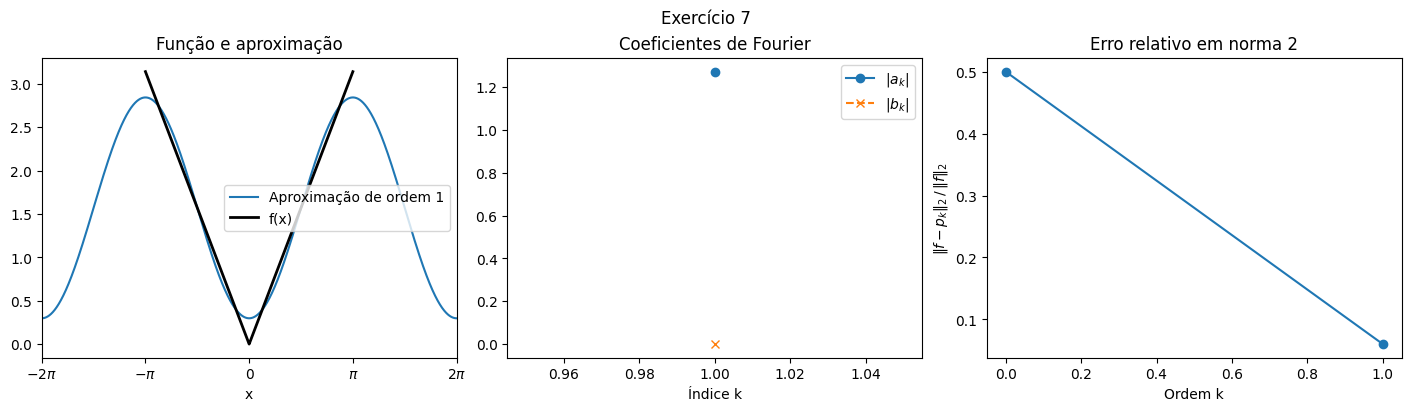

In [ ]:
# Função a ser aproximada em [-pi, pi]
def f(x):
    return ...

# Funções para calcular os integrandos
def fc(x):
    return ...

def fs(x):
    return ...

k = 0
a0 = ...

k = 1
a1 = ...
b1 = ...

print(f"a0 = {a0:.12f}, a1 = {a1:.12f}, b1 = {b1:.12f}")

# Execute esta celula para visualizar a função e a aproximação
_ = diagnostico(f, [a0, a1], [0.0, b1], "Exercício 7")

**Resposta — Exercício 7:** escreva suas observações sobre simetria e qualidade do ajuste.

## Exercícios 8 e 9 — Influência da ordem do polinômio

Considere novamente $f(x)=|x|$ em $[-\pi,\pi]$.

**Tarefa 003 — Generalização.** Generalize o cálculo anterior para ordem arbitrária $m$, armazenando os coeficientes em $\mathbf a=(a_0,\ldots,a_m)$ e $\mathbf b=(0,b_1,\ldots,b_m)$. Experimente as ordens **$m=1,3,10,30$** e execute a rotina de diagnóstico em cada caso.

**Analise:** (a) Como a qualidade da aproximação evolui? (b) O que os coeficientes indicam sobre a simetria de $f$? (c) O erro relativo diminui sempre na mesma proporção? (d) A extensão periódica de $|x|$ é contínua?

In [ ]:
# Função a ser aproximada em [-pi, pi]
def f(x):
    return np.abs(x)

# Funções para calcular os integrandos
def fc(x):
    return f(x)*np.cos(k*x)

def fs(x):
    return f(x)*np.sin(k*x)

ordem = 10
a = ...
b = ...

k = 0
a[0] = ...
for k in range(1, ordem + 1):

# Execute esta celula para visualizar a função e a aproximação
_ = diagnostico(f, a, b, f"Exercícios 8 e 9 — m={ordem}")

# Repita para ordem = 1, 3, 10 e 30.

**Resposta — Exercícios 8 e 9:** registre as conclusões sobre ordem, coeficientes e extensão periódica.

## Exercício 10 — Aproximação de uma função ímpar

Considere $f(x)=x$, para $x\in[-\pi,\pi]$.

**Tarefa 004.** Adapte o código anterior para calcular os coeficientes de Fourier. Construa inicialmente $p_{10}$ e compare com as ordens **$m=30$ e $m=50$**. Observe a aproximação em $[-2\pi,2\pi]$.

**Analise:** (a) Quais coeficientes deveriam ser nulos, considerando a paridade de $f$? (b) Como a aproximação se comporta perto de $x=\pm\pi$? (c) Sua extensão periódica é contínua? (d) Compare com $f(x)=|x|$: qual função apresenta maior dificuldade de aproximação nas extremidades?

In [ ]:
# Função a ser aproximada em [-pi, pi]
def f(x):
    return ...

# Funções para calcular os integrandos
def fc(x):
    return f(x)*np.cos(k*x)

def fs(x):
    return f(x)*np.sin(k*x)

ordem = 10

...
...
...
...

# Execute esta celula para visualizar a função e a aproximação
_ = diagnostico(f, a, b, "Exercício 10")

# Repita para ordem = 10, 30 e 50.

**Resposta — Exercício 10:** registre as conclusões sobre paridade, descontinuidades e oscilações.

## Exercício 11 — Aproximação em um intervalo arbitrário

Considere $f(t)=t^2$ em $t\in[-1,1]$. Para aplicar as fórmulas em $[-\pi,\pi]$, utilize

$$t(x)=\frac{b-a}{2\pi}(x+\pi)+a,\qquad h(x)=f(t(x)),$$

com $a=-1$ e $b=1$.

**Tarefa 005 — Mudança de variável.** Implemente $t(x)$ e $h(x)$. Verifique os valores de $t(-\pi)$, $t(0)$ e $t(\pi)$.

**Tarefa 006 — Calcule os coeficientes de Fourier de $h(x)$.**

Use `quadgauss` para aproximar as integrais no intervalo $[-\pi,\pi]$.

1. Calcule $a_0$ integrando $h(x)$ e dividindo o resultado por $\pi$.
   Lembre-se de que o termo constante do polinômio é $a_0/2$.
2. Para cada $k$ de 1 até a ordem $m$, calcule $a_k$ integrando
   $h(x)\cos(kx)$ e $b_k$ integrando $h(x)\operatorname{sen}(kx)$.
   Divida cada integral por $\pi$ e guarde os resultados em `a[k]` e `b[k]`.
3. Comece com $m=10$ e execute `diagnostico`. Repita para $m=30$ e $m=100$.
   O que você espera observar nos valores de $b_k$, sabendo que $h$ é par?
4. Mantenha $m=100$ e refaça o cálculo com 200 e com 400 pontos de
   quadratura. Compare os coeficientes e o erro relativo obtidos.
   Aumentar o número de pontos mudou sensivelmente o resultado?

**Analise:** (a) O que a mudança de variável faz com o domínio? (b) A extensão periódica de $h$ é contínua? (c) Como evolui o erro relativo? (d) Como recuperar uma aproximação de $f(t)$ no intervalo original?

In [ ]:
# Função a ser aproximada em [-pi, pi]
def f(x):
    return ...

def h(x):
  a = ...
  b = ...
  t = ...
  return f(t)

# Funções para calcular os integrandos
def hc(x):
    return h(x)*np.cos(k*x)

def hs(x):
    return h(x)*np.sin(k*x)

ordem = 10
a = np.zeros(ordem+1)
b = np.zeros(ordem+1)

k = 0
a[0] = ...
for k in range(1, ordem+1):
  a[k] = ...
  b[k] = ...

# Execute esta celula para visualizar a função e a aproximação
_ = diagnostico(h, a, b, f"Exercício 11 — m={ordem}")

# Repita para ordem = 10, 30 e 100.

## Conclusão

Explique, em poucas frases: **por que o aumento da ordem do polinômio trigonométrico nem sempre resulta em uma melhora visual significativa da aproximação em todos os pontos?** Considere a regularidade da extensão periódica, as oscilações próximas às descontinuidades e os erros de integração numérica.


---

# Atividade complementar — Ajuste de dados periódicos por mínimos quadrados
Neste problema, usamos observações discretas. Avaliar as funções de base para montar as colunas de $A$, formar o sistema normal e resolver para os coeficientes.

Considere uma corrente idealizada de período $T=1$ s, par em torno de $t=0$. Há 32 leituras sintéticas em mA, obtidas em instantes igualmente espaçados e sujeitas a pequenas perturbações. Desejamos ajustar

$$q_m(t)=\sum_{k=0}^{m}a_k\cos\!\left(\frac{2\pi kt}{T}\right).$$

Execute a célula a seguir para gerar as amostras.

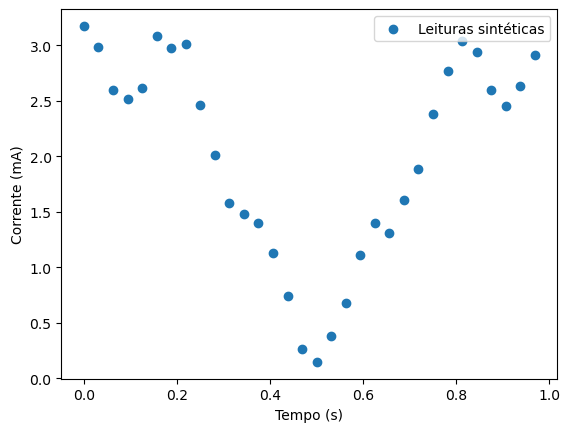

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

T = 1.0
mm = 32
x = np.arange(mm) * T / mm
theta = 2 * np.pi * x / T
rng = np.random.default_rng(30)
fx = (2 + 1.2 * np.cos(theta) - 0.45 * np.cos(2 * theta)
      + 0.30 * np.cos(5 * theta) + rng.normal(0, 0.08, mm))

plt.scatter(x, fx, label="Leituras sintéticas")
plt.xlabel("Tempo (s)")
plt.ylabel("Corrente (mA)")
plt.legend()
plt.show()

## Complementar 1 — Monte e resolva o ajuste de ordem 2

Aqui **x** guarda os tempos, **fx** guarda as leituras, **mm** conta os dados e **nn** conta as funções de base. Para ordem 2 temos **nn = 3**, pois usamos $1$, $\cos(2\pi t/T)$ e $\cos(4\pi t/T)$.

Antes de executar, escreva a primeira linha de $A$ e suas dimensões. A função **phi(x, j)** avalia a função de índice $j$ em todos os tempos.
Confira a primeira linha impressa e interprete os produtos $A^\mathsf{T}r$ para $r=\mathbf{fx}-Ac$.

Dimensões de A: (32, 3)
Primeira linha de A: [1. 1. 1.]
Coeficientes: [ 2.00953571  1.18193312 -0.42687623]
A.T @ r: [-7.88258347e-15 -3.08086889e-15  2.80331314e-15]
Soma dos quadrados: 1.665462659603563


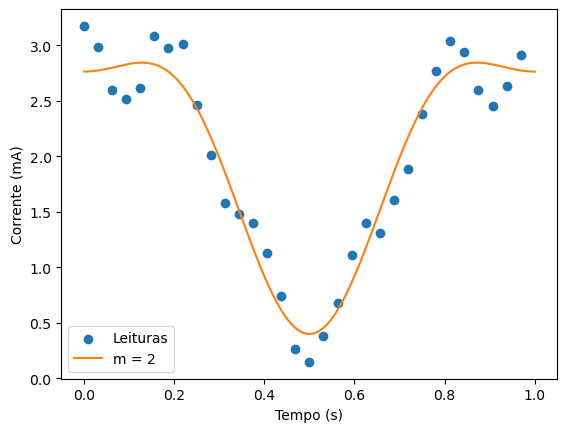

In [ ]:
def phi(x, j):
    return np.cos(2 * np.pi * j * x / T)

def montar_A(tempos, nn):
    A = np.zeros((len(tempos), nn))
    for j in range(nn):
        A[:, j] = phi(tempos, j)
    return A

nn = 3
A = montar_A(x, nn)
N = ...
b = ...
c = np.linalg.solve(N, b)

r = fx - A @ c
print("Dimensões de A:", A.shape)
print("Primeira linha de A:", A[0])
print("Coeficientes:", c)
print("A.T @ r:", A.T @ r)
print("Soma dos quadrados:", r @ r)

grade = np.linspace(0, T, 401)
q2_grade = montar_A(grade, nn) @ c
plt.scatter(x, fx, label="Leituras")
plt.plot(grade, q2_grade, color="tab:orange", label="m = 2")
plt.xlabel("Tempo (s)")
plt.ylabel("Corrente (mA)")
plt.legend()
plt.show()

## Complementar 2 — Generalize a matriz e calcule os erros

Para cada ordem $m$, use **nn = m + 1** na mesma rotina que monta $A$. Complete as linhas de previsão, resíduo e métricas. Para cada $m=1,\ldots,10$, calcule $\Phi_m=\sum_j (y_j-q_m(t_j))^2$ e $E_{\infty,m}=\max_j|y_j-q_m(t_j)|$. Organize os valores em tabela.

In [ ]:
ordens = np.arange(1, 11)
coeficientes = {}
somas_quadrados = []
erros_maximos = []

for m in ordens:
    nn = m + 1
    A = montar_A(x, nn)
    N = A.T @ A
    b = A.T @ fx
    c = np.linalg.solve(N, b)

    y_ajustado = ...            # Previsão nos tempos amostrados
    r = ...                     # Resíduo em cada amostra
    soma_quadrados = ...        # Produto escalar: soma de r[j]²
    erro_maximo = ...           # Maior distância entre leitura e ajuste

    coeficientes[m] = c
    somas_quadrados.append(soma_quadrados)
    erros_maximos.append(erro_maximo)

print(f"{'m':>2} {'Phi (mA²)':>12} {'E_inf (mA)':>12}")
for m, soma, maior in zip(ordens, somas_quadrados, erros_maximos):
    print(f"{m:2d} {soma:12.6f} {maior:12.6f}")

 m    Phi (mA²)   E_inf (mA)
 1     4.581036     0.769239
 2     1.665463     0.411379
 3     1.662652     0.424633
 4     1.656616     0.405211
 5     0.149825     0.197736
 6     0.129573     0.164867
 7     0.115033     0.141781
 8     0.108548     0.141781
 9     0.105469     0.155385
10     0.105468     0.155289


## Complementar 3 — Compare as ordens

Compare as aproximações para $m=1,2,5,10$. Identifique as maiores reduções de $\Phi_m$, investigue se $E_{\infty,m}$ tem o mesmo comportamento e justifique uma escolha de ordem considerando precisão e número de coeficientes.

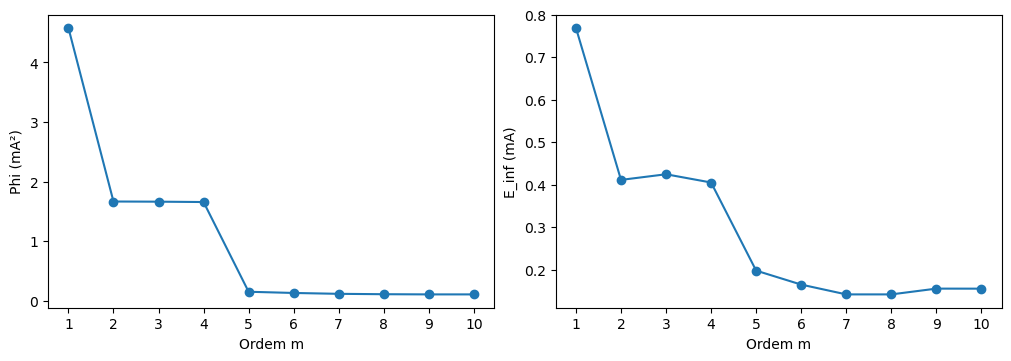

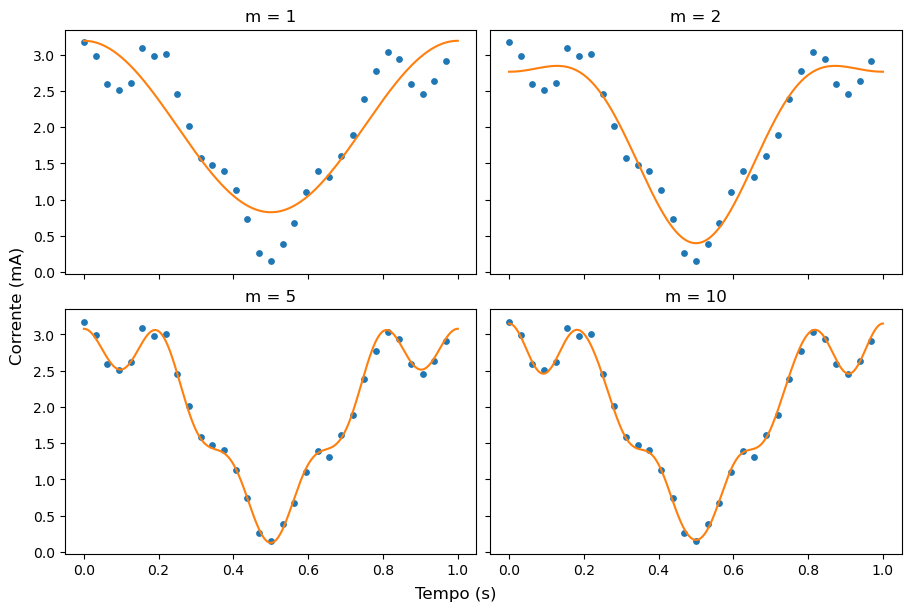

Coeficientes para m = 10: [ 2.0095e+00  1.1819e+00 -4.2690e-01 -1.3300e-02  1.9400e-02  3.0690e-01
  3.5600e-02  3.0100e-02  2.0100e-02 -1.3900e-02  3.0000e-04]


In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for eixo, valores, rotulo in zip(
    eixos, [somas_quadrados, erros_maximos], ["Phi (mA²)", "E_inf (mA)"]
):
    eixo.plot(ordens, valores, marker="o")
    eixo.set(xlabel="Ordem m", ylabel=rotulo, xticks=ordens)
plt.show()

fig, eixos = plt.subplots(2, 2, figsize=(9, 6), sharex=True, sharey=True,
                         layout="constrained")
for eixo, m in zip(eixos.flat, [1, 2, 5, 10]):
    eixo.scatter(x, fx, s=15)
    eixo.plot(grade, montar_A(grade, m + 1) @ coeficientes[m],
              color="tab:orange")
    eixo.set_title(f"m = {m}")
fig.supxlabel("Tempo (s)")
fig.supylabel("Corrente (mA)")
plt.show()

print("Coeficientes para m = 10:", np.round(coeficientes[10], 4))

## Complementar 4 — Influência da distribuição dos pontos (Para a entrega)

Examine $A^\mathsf{T}A$ para $m=2$ e $m=10$ com amostragem uniforme. Depois desloque apenas $t_1$ de $T/(4\,\mathrm{mm})$ e reconstrua $A$ para $m=2$ com **montar_A** e **nn = 3**. Compare os elementos diagonais e não diagonais e explique a relação entre amostragem e ortogonalidade discreta. Registre sua ordem escolhida e a justificativa.

In [ ]:
def resumo_gram(A):
    G = A.T @ A
    diagonal = np.diag(G)
    fora = G - np.diag(diagonal)
    print("Diagonal:", np.round(diagonal, 6))
    print("Maior |entrada fora da diagonal|:", np.max(np.abs(fora)))

for m in [2, 10]:
    print(f"Malha uniforme, m = {m}")
    resumo_gram(montar_A(x, m + 1))

x_alterado = x.copy()
x_alterado[1] += T / (4 * mm)
A_alterada = ...


print("Malha perturbada, m = 2")
resumo_gram(A_alterada)

Malha uniforme, m = 2
Diagonal: [32. 16. 16.]
Maior |entrada fora da diagonal|: 2.55351295663786e-15
Malha uniforme, m = 10
Diagonal: [32. 16. 16. 16. 16. 16. 16. 16. 16. 16. 16.]
Maior |entrada fora da diagonal|: 2.077199395730606e-14
Malha perturbada, m = 2
Diagonal: [32.       15.979021 15.924232 15.857667 15.808658 15.804836 15.863161
 15.98347  16.146447 16.316797 16.451099]
Maior |entrada fora da diagonal|: 0.40060898247630017


**Resposta da dupla:** ordem escolhida e justificativa; efeito da alteração da malha.